In [ ]:
import copy
import io
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torchvision.models import ResNet18_Weights, resnet18


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [ ]:
FAST_MODE = False

BATCH_SIZE = 32
HEAD_EPOCHS = 2 if FAST_MODE else 5
FINE_TUNE_EPOCHS = 1 if FAST_MODE else 3

TRAIN_LIMIT = 1200 if FAST_MODE else None
VAL_LIMIT = 400 if FAST_MODE else None
TEST_LIMIT = 400 if FAST_MODE else None


In [ ]:
weights = ResNet18_Weights.DEFAULT
eval_transform = weights.transforms()

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


In [ ]:
DATA_ROOT = "./data"

# Separate dataset objects let training and validation use different transforms.
raw_trainval = OxfordIIITPet(
    DATA_ROOT, split="trainval", target_types="category", download=True
)
train_dataset = OxfordIIITPet(
    DATA_ROOT, split="trainval", target_types="category",
    transform=train_transform
)
val_dataset = OxfordIIITPet(
    DATA_ROOT, split="trainval", target_types="category",
    transform=eval_transform
)
test_dataset = OxfordIIITPet(
    DATA_ROOT, split="test", target_types="category",
    transform=eval_transform, download=True
)

class_names = raw_trainval.classes
num_classes = len(class_names)

print("Classes:", num_classes)
print("Trainval images:", len(raw_trainval))
print("Test images:", len(test_dataset))
print("First five breeds:", class_names[:5])


100%|██████████| 792M/792M [00:45<00:00, 17.5MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 7.93MB/s]


Classes: 37
Trainval images: 3680
Test images: 3669
First five breeds: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


In [ ]:
generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(raw_trainval), generator=generator).tolist()

val_size = int(0.20 * len(permutation))
val_indices = permutation[:val_size]
train_indices = permutation[val_size:]

if FAST_MODE:
    train_indices = train_indices[:TRAIN_LIMIT]
    val_indices = val_indices[:VAL_LIMIT]
    test_indices = torch.randperm(
        len(test_dataset), generator=generator
    )[:TEST_LIMIT].tolist()
    test_dataset = Subset(test_dataset, test_indices)

train_dataset = Subset(train_dataset, train_indices)
val_dataset = Subset(val_dataset, val_indices)

loaders = {
    "train": DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=2, pin_memory=torch.cuda.is_available()
    ),
    "val": DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=2, pin_memory=torch.cuda.is_available()
    ),
    "test": DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=2, pin_memory=torch.cuda.is_available()
    ),
}

print({name: len(loader.dataset) for name, loader in loaders.items()})


{'train': 2944, 'val': 736, 'test': 3669}


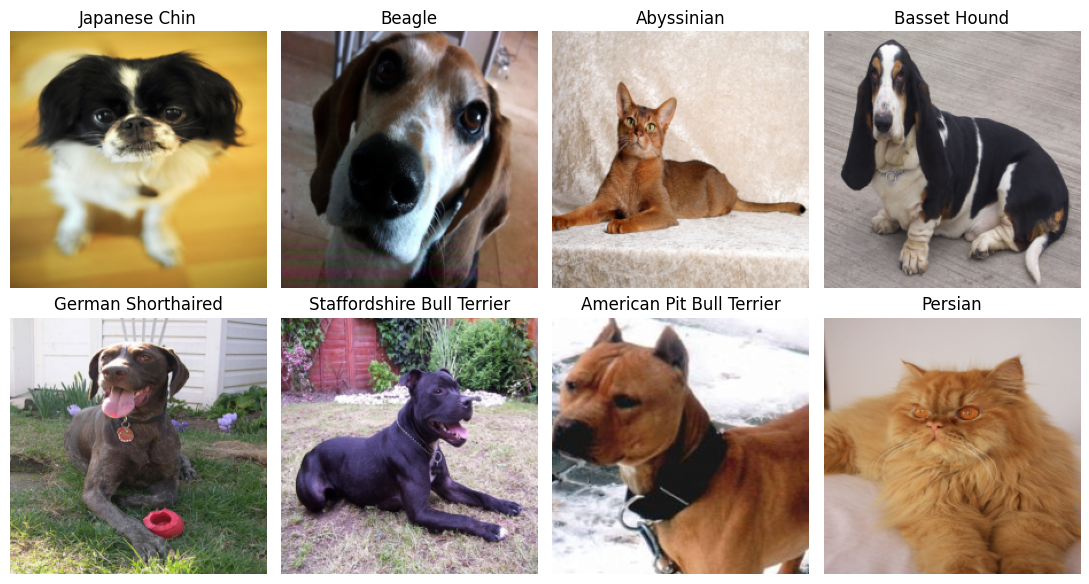

In [ ]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225])[:, None, None]


def denormalize(image):
    image = image.cpu() * IMAGENET_STD + IMAGENET_MEAN
    return image.clamp(0, 1)

images, labels = next(iter(loaders["train"]))

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for image, label, ax in zip(images[:8], labels[:8], axes.flat):
    ax.imshow(denormalize(image).permute(1, 2, 0))
    ax.set_title(class_names[label.item()].replace("_", " "))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def build_head_only_model(pretrained):
    chosen_weights = weights if pretrained else None
    network = resnet18(weights=chosen_weights) # loading the arch with/without pretrained weights

    for parameter in network.parameters():
        parameter.requires_grad = False # freezing the model

    network.fc = nn.Linear(network.fc.in_features, num_classes) # replacing the head
    return network.to(device)



In [ ]:
network = resnet18(weights=weights)
network

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 141MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [ ]:
network.fc

Linear(in_features=512, out_features=1000, bias=True)

In [ ]:
model = build_head_only_model(pretrained=True)
random_model = build_head_only_model(pretrained=False)

# Give both experiments the same initial classifier values.
random_model.fc.load_state_dict(copy.deepcopy(model.fc.state_dict()))

<All keys matched successfully>

In [ ]:
def parameter_summary(network):
    total = sum(parameter.numel() for parameter in network.parameters())
    trainable = sum(
        parameter.numel()
        for parameter in network.parameters()
        if parameter.requires_grad
    )
    return total, trainable, 100 * trainable / total


In [ ]:
total, trainable, percentage = parameter_summary(model)
print(f"Total parameters:     {total:,}")
print(f"Trainable parameters: {trainable:,}")
print(f"Trainable percentage: {percentage:.3f}%")

print("\nTrainable tensors:")
for name, parameter in model.named_parameters():
    if parameter.requires_grad:
        print(f"  {name:10s} {tuple(parameter.shape)}")

Total parameters:     11,195,493
Trainable parameters: 18,981
Trainable percentage: 0.170%

Trainable tensors:
  fc.weight  (37, 512)
  fc.bias    (37,)


In [ ]:
loss_function = nn.CrossEntropyLoss()

probe_inputs, probe_targets = next(iter(loaders["train"]))
probe_inputs = probe_inputs.to(device)
probe_targets = probe_targets.to(device)


In [ ]:
probe_inputs.shape, probe_targets.shape

(torch.Size([32, 3, 224, 224]), torch.Size([32]))

In [ ]:
probe_targets

tensor([31, 36, 33, 32,  1, 20,  4, 27, 32, 18, 14, 12, 32, 25, 24,  8, 33,  2,
        25, 24, 20, 27, 24,  1,  3, 15,  7, 14, 32, 15,  6,  5],
       device='cuda:0')

In [ ]:
# model.eval()
model.zero_grad(set_to_none=True)
probe_loss = loss_function(model(probe_inputs), probe_targets)
probe_loss.backward()

In [ ]:
probe_loss

tensor(3.8634, device='cuda:0', grad_fn=<NllLossBackward0>)

In [ ]:
print("conv1 gradient:", model.conv1.weight.grad)
print("fc gradient norm:", model.fc.weight.grad.norm().item())

conv1 gradient: None
fc gradient norm: 5.2456207275390625


In [ ]:
model.zero_grad(set_to_none=True)

In [ ]:
def run_epoch(network, loader, optimizer=None, trainable_children=None):
    is_training = optimizer is not None

    if is_training:
        network.train()
        if trainable_children is not None:
            for name, module in network.named_children():
                if name not in trainable_children:
                    module.eval()
    else:
        network.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for inputs, targets in loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            logits = network(inputs)
            loss = loss_function(logits, targets)

            if is_training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * inputs.size(0)
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
        total_examples += inputs.size(0)

    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples,
    }


In [ ]:
def fit(network, optimizer, epochs, trainable_children=None):
    history = {"train_loss": [], "val_loss": [],
               "train_accuracy": [], "val_accuracy": []}
    best_state = copy.deepcopy(network.state_dict())
    best_val_accuracy = -1.0

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(
            network, loaders["train"], optimizer,
            trainable_children=trainable_children,
        )
        val_metrics = run_epoch(network, loaders["val"])

        history["train_loss"].append(train_metrics["loss"])
        history["val_loss"].append(val_metrics["loss"])
        history["train_accuracy"].append(train_metrics["accuracy"])
        history["val_accuracy"].append(val_metrics["accuracy"])

        if val_metrics["accuracy"] > best_val_accuracy:
            best_val_accuracy = val_metrics["accuracy"]
            best_state = copy.deepcopy(network.state_dict())

        print(
            f"Epoch {epoch:02d} | "
            f"train loss {train_metrics['loss']:.3f} | "
            f"train acc {train_metrics['accuracy']:.3f} | "
            f"val loss {val_metrics['loss']:.3f} | "
            f"val acc {val_metrics['accuracy']:.3f}"
        )

    network.load_state_dict(best_state)
    return history

In [ ]:
for parameter in random_model.parameters():
    parameter.requires_grad = True # unfreezing the model

print("RANDOM FROZEN FEATURES")
random_optimizer = torch.optim.AdamW(
    random_model.parameters(), lr=1e-3, weight_decay=1e-4
)
random_history = fit(
    random_model,
    optimizer=random_optimizer,
    epochs=HEAD_EPOCHS,
    # trainable_children=("fc",),
)

RANDOM FROZEN FEATURES
Epoch 01 | train loss 3.609 | train acc 0.068 | val loss 3.747 | val acc 0.077
Epoch 02 | train loss 3.293 | train acc 0.106 | val loss 3.617 | val acc 0.086
Epoch 03 | train loss 3.155 | train acc 0.133 | val loss 3.420 | val acc 0.106
Epoch 04 | train loss 3.028 | train acc 0.160 | val loss 3.352 | val acc 0.107
Epoch 05 | train loss 2.944 | train acc 0.167 | val loss 3.257 | val acc 0.144


In [ ]:
print("\nPRETRAINED FROZEN FEATURES")
head_optimizer = torch.optim.AdamW(
    model.fc.parameters(), lr=1e-3, weight_decay=1e-4
)
head_history = fit(
    model,
    optimizer=head_optimizer,
    epochs=HEAD_EPOCHS,
    trainable_children=("fc",),
)



PRETRAINED FROZEN FEATURES
Epoch 01 | train loss 1.857 | train acc 0.585 | val loss 0.890 | val acc 0.829
Epoch 02 | train loss 0.626 | train acc 0.870 | val loss 0.524 | val acc 0.893
Epoch 03 | train loss 0.420 | train acc 0.916 | val loss 0.423 | val acc 0.901
Epoch 04 | train loss 0.321 | train acc 0.931 | val loss 0.373 | val acc 0.908
Epoch 05 | train loss 0.269 | train acc 0.942 | val loss 0.331 | val acc 0.908


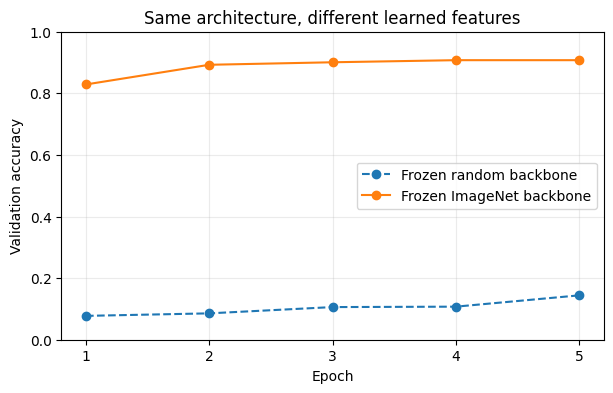

In [ ]:
epochs = np.arange(1, HEAD_EPOCHS + 1)

plt.figure(figsize=(7, 4))
plt.plot(
    epochs, random_history["val_accuracy"], "o--",
    label="Frozen random backbone"
)
plt.plot(
    epochs, head_history["val_accuracy"], "o-",
    label="Frozen ImageNet backbone"
)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Same architecture, different learned features")
plt.xticks(epochs)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.show()


In [ ]:
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

total, trainable, percentage = parameter_summary(model)
print(f"Trainable after unfreezing layer4: {trainable:,} ({percentage:.2f}%)")

Trainable after unfreezing layer4: 8,412,709 (75.14%)


In [ ]:
fine_tune_optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4},
], weight_decay=1e-4)

fine_tune_history = fit(
    model,
    optimizer=fine_tune_optimizer,
    epochs=FINE_TUNE_EPOCHS,
    trainable_children=("layer4", "fc"),
)



Epoch 01 | train loss 0.360 | train acc 0.935 | val loss 0.360 | val acc 0.916
Epoch 02 | train loss 0.285 | train acc 0.946 | val loss 0.329 | val acc 0.918
Epoch 03 | train loss 0.245 | train acc 0.954 | val loss 0.307 | val acc 0.923


NameError: name 'head_val_accuracy' is not defined

In [ ]:
head_val_accuracy = max(head_history["val_accuracy"])
fine_tuned_val_accuracy = max(fine_tune_history["val_accuracy"])
print(f"Head-only best val accuracy: {head_val_accuracy:.3f}")
print(f"Fine-tuning best val accuracy: {fine_tuned_val_accuracy:.3f}")

Head-only best val accuracy: 0.908
Fine-tuning best val accuracy: 0.923


In [ ]:
test_metrics = run_epoch(model, loaders["test"])

print(f"Test loss: {test_metrics['loss']:.3f}")
print(f"Test accuracy: {test_metrics['accuracy']:.3f}")


Test loss: 0.364
Test accuracy: 0.900


In [ ]:
activations = {}
gradients = {}


def save_activation(module, inputs, output):
    activations["value"] = output
    if output.requires_grad:
        output.register_hook(
            lambda grad: gradients.update({"value": grad})
        )


if "gradcam_hook" in globals():
    gradcam_hook.remove()

target_layer = model.layer4[-1].conv2
gradcam_hook = target_layer.register_forward_hook(save_activation)


def make_gradcam(network, image, target_class=None):
    network.eval()
    network.zero_grad(set_to_none=True)

    logits = network(image.unsqueeze(0).to(device))
    predicted_class = logits.argmax(dim=1).item()

    if target_class is None:
        target_class = predicted_class

    logits[0, target_class].backward()

    feature_maps = activations["value"][0]
    feature_gradients = gradients["value"][0]
    channel_weights = feature_gradients.mean(dim=(1, 2), keepdim=True)

    cam = torch.relu((channel_weights * feature_maps).sum(dim=0))
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(
        cam[None, None],
        size=image.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )[0, 0]

    return cam.detach().cpu(), predicted_class


In [ ]:
def collect_examples(network, loader, count=4):
    examples = {"correct": [], "wrong": []}
    network.eval()

    with torch.no_grad():
        for inputs, targets in loader:
            probabilities = network(inputs.to(device)).softmax(dim=1).cpu()
            confidence, predictions = probabilities.max(dim=1)

            for image, target, prediction, score in zip(
                inputs, targets, predictions, confidence
            ):
                key = "correct" if prediction.item() == target.item() else "wrong"
                if len(examples[key]) < count:
                    examples[key].append({
                        "image": image,
                        "true": target.item(),
                        "predicted": prediction.item(),
                        "confidence": score.item(),
                    })

            if all(len(group) >= count for group in examples.values()):
                break

    return examples


examples = collect_examples(model, loaders["test"], count=4)

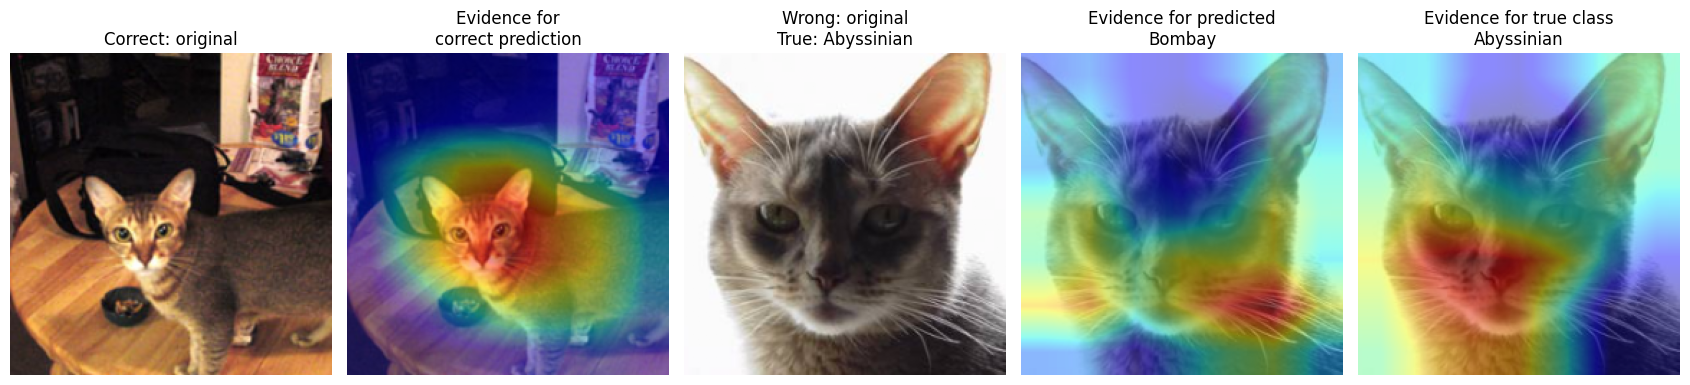

In [ ]:
correct_item = examples["correct"][0]
wrong_item = examples["wrong"][0]

correct_cam, _ = make_gradcam(
    model, correct_item["image"], correct_item["predicted"]
)
wrong_predicted_cam, _ = make_gradcam(
    model, wrong_item["image"], wrong_item["predicted"]
)
wrong_true_cam, _ = make_gradcam(
    model, wrong_item["image"], wrong_item["true"]
)

correct_image = denormalize(correct_item["image"]).permute(1, 2, 0)
wrong_image = denormalize(wrong_item["image"]).permute(1, 2, 0)

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

axes[0].imshow(correct_image)
axes[0].set_title("Correct: original")
axes[1].imshow(correct_image)
axes[1].imshow(correct_cam, cmap="jet", alpha=0.45)
axes[1].set_title("Evidence for\ncorrect prediction")

axes[2].imshow(wrong_image)
axes[2].set_title(
    f"Wrong: original\nTrue: {class_names[wrong_item['true']]}"
)
axes[3].imshow(wrong_image)
axes[3].imshow(wrong_predicted_cam, cmap="jet", alpha=0.45)
axes[3].set_title(
    f"Evidence for predicted\n{class_names[wrong_item['predicted']]}"
)
axes[4].imshow(wrong_image)
axes[4].imshow(wrong_true_cam, cmap="jet", alpha=0.45)
axes[4].set_title(
    f"Evidence for true class\n{class_names[wrong_item['true']]}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Saving dog6.png to dog6.png
Uploaded: dog6.png


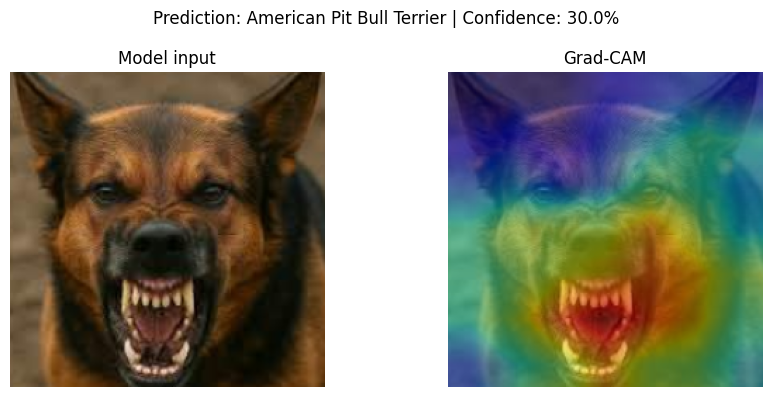

In [ ]:
def predict_uploaded_image(pil_image):
    image = eval_transform(pil_image.convert("RGB"))

    model.eval()
    with torch.no_grad():
        probabilities = model(image.unsqueeze(0).to(device)).softmax(dim=1)[0]
        confidence, predicted_class = probabilities.max(dim=0)

    cam, _ = make_gradcam(model, image, predicted_class.item())
    display_image = denormalize(image).permute(1, 2, 0)

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(display_image)
    axes[0].set_title("Model input")
    axes[1].imshow(display_image)
    axes[1].imshow(cam, cmap="jet", alpha=0.45)
    axes[1].set_title("Grad-CAM")
    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"Prediction: {class_names[predicted_class.item()].replace('_', ' ')} | "
        f"Confidence: {confidence.item():.1%}"
    )
    plt.tight_layout()
    plt.show()


try:
    from google.colab import files

    uploaded = files.upload()
    if uploaded:
        filename, file_bytes = next(iter(uploaded.items()))
        print("Uploaded:", filename)
        predict_uploaded_image(Image.open(io.BytesIO(file_bytes)))
except ImportError:
    print("Upload helper skipped: run this cell in Google Colab.")
